PARTICLE SWARM OPTIMIZATION RESULTS
-----------------------------------
Best Position (x): 8.367238857156422e-11
Minimum Function Value: 7.00106860927083e-21

Theoretical Optimal Position: 0
Theoretical Minimum Value: 0


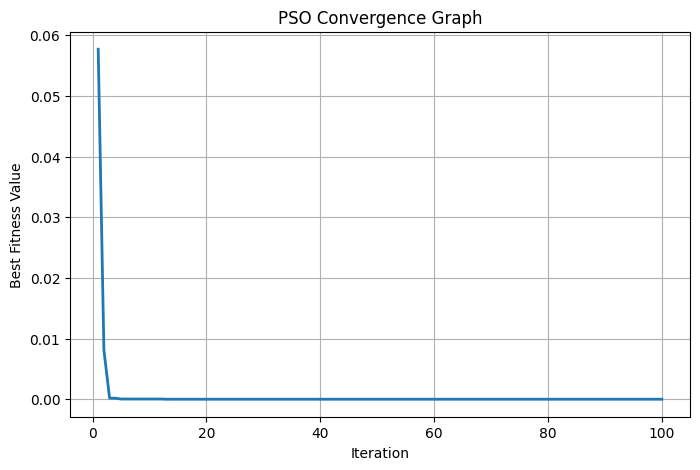

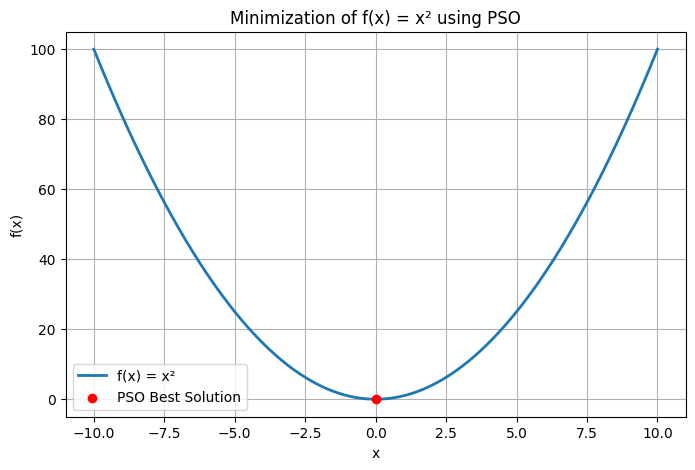

In [3]:

import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# PARTICLE SWARM OPTIMIZATION (PSO)
# Problem: Minimize f(x) = x^2
# Search space: -10 <= x <= 10
# ---------------------------------------

# 1. Define the objective function
def objective_function(x):
    return x ** 2


# 2. Set PSO parameters
np.random.seed(42)

swarm_size = 30
max_iterations = 100

w = 0.7       # Inertia weight
c1 = 1.5      # Cognitive coefficient
c2 = 1.5      # Social coefficient

lower_bound = -10
upper_bound = 10


# 3. Initialize particle positions and velocities
positions = np.random.uniform(
    lower_bound, upper_bound, swarm_size
)

velocities = np.random.uniform(-1, 1, swarm_size)


# 4. Initialize personal best positions
personal_best_positions = positions.copy()

personal_best_values = objective_function(positions)


# 5. Find the initial global best
best_index = np.argmin(personal_best_values)

global_best_position = personal_best_positions[best_index]
global_best_value = personal_best_values[best_index]


# Store best values for convergence graph
convergence_history = []


# 6. Main PSO iteration loop
for iteration in range(max_iterations):

    for i in range(swarm_size):

        # Generate random numbers
        r1 = np.random.random()
        r2 = np.random.random()

        # Update velocity
        velocities[i] = (
            w * velocities[i]
            + c1 * r1 * (
                personal_best_positions[i] - positions[i]
            )
            + c2 * r2 * (
                global_best_position - positions[i]
            )
        )

        # Update particle position
        positions[i] = positions[i] + velocities[i]

        # Keep particles within search boundaries
        positions[i] = np.clip(
            positions[i], lower_bound, upper_bound
        )

        # Calculate new fitness value
        current_value = objective_function(positions[i])

        # Update personal best
        if current_value < personal_best_values[i]:

            personal_best_values[i] = current_value
            personal_best_positions[i] = positions[i]

        # Update global best
        if current_value < global_best_value:

            global_best_value = current_value
            global_best_position = positions[i]

    # Save the best value of this iteration
    convergence_history.append(global_best_value)


# 7. Display final results
print("PARTICLE SWARM OPTIMIZATION RESULTS")
print("-----------------------------------")

print("Best Position (x):", global_best_position)
print("Minimum Function Value:", global_best_value)

print("\nTheoretical Optimal Position: 0")
print("Theoretical Minimum Value: 0")


# 8. Plot convergence graph
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, max_iterations + 1),
    convergence_history,
    linewidth=2
)

plt.xlabel("Iteration")
plt.ylabel("Best Fitness Value")
plt.title("PSO Convergence Graph")
plt.grid(True)

plt.show()


# 9. Plot objective function and best solution
x_values = np.linspace(-10, 10, 400)
y_values = objective_function(x_values)

plt.figure(figsize=(8, 5))

plt.plot(
    x_values,
    y_values,
    label="f(x) = x²",
    linewidth=2
)

plt.scatter(
    global_best_position,
    global_best_value,
    color="red",
    label="PSO Best Solution",
    zorder=3
)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Minimization of f(x) = x² using PSO")
plt.legend()
plt.grid(True)

plt.show()
